## Arquitetura da parametrização do modelo de árvore

### Por que este método
Modelos de árvore (boosting) têm dezenas de hiperparâmetros, mas a maior parte do ganho vem de poucos. Por isso esse método de parametrização **foca nos 3 principais**:

| Parâmetro | O que controla |
|---|---|
| **learning_rate** | Quanto cada árvore nova corrige o erro das anteriores. Valores menores aprendem mais devagar e pedem mais árvores |
| **n_estimators** | Quantidade de árvores. Poucas deixam o modelo fraco (underfitting); árvores demais passam a decorar o treino (overfitting) |
| **max_depth** | Quantas divisões (perguntas) cada árvore faz até chegar numa folha. Mais profundidade captura mais interações entre variáveis, mas aumenta o risco de overfitting |

Os demais hiperparâmetros ficam no **default**.

### Como funciona
- **Resumo:** para cada learning rate existe uma combinação de n_estimators e max_depth que leva ao menor erro antes do overfitting. Combinações diferentes desses 3 parâmetros chegam a erros semelhantes; o que muda é o caminho. Com LR = 0,05 o modelo precisa de menos árvores que com LR = 0,01 para chegar ao ponto de overfitting, e o erro mínimo fica numa faixa parecida (LR menor costuma ficar levemente abaixo, ao custo de mais árvores). Por isso não é preciso testar todas as combinações (grid), basta achar esse ponto um parâmetro de cada vez.
- **Um parâmetro de cada vez:** os outros ficam travados, e só o parâmetro da vez varia dentro de um range.
- **Curva de erro:** a cada passo (de 1 a 10 árvores adicionadas, conforme o tamanho do problema), o erro de validação é plotado e acompanhado até o ponto em que adicionar árvores deixa de compensar. A curva plotada é a média do erro de validação dos 5 folds para aquele número de árvores.
- **Early stopping:** o treino para quando a melhora fica abaixo de um limiar por N passos seguidos (paciência), ou seja, quando o erro de validação começa a estabilizar ou subir. O limiar (0,08% a 1%) e a paciência (3 a 10) acompanham o tamanho do passo: passos pequenos geram melhoras pequenas por passo, então pedem limiar menor e paciência maior. Entre dois valores com desempenho parecido, fica o mais simples.
- **Validação honesta:** todas as escolhas usam K-fold (k = 5). O conjunto de teste (holdout) é separado no início, fica fora de toda a parametrização e só entra no final, para medir de forma honesta o desempenho do modelo em dados nunca vistos no treino nem na parametrização.
- **Reprodutibilidade:** uma seed fixa (`SEED`) é usada no split treino/teste, no K-fold (`shuffle=True, random_state=SEED`) e no `random_state` do modelo. Assim, toda execução gera os mesmos folds, as mesmas curvas e o mesmo resultado.

```
               ┌──────────────── Base de dados (split com SEED) ────────────────┐
               │                                                                 │
            Treino                                                  Teste reservado (holdout)
               │                                                    separado no início,
               │                                                    fora da parametrização
               ▼                                                                 │
╔═════ Parametrização: K-fold (k = 5, shuffle, SEED) dentro do treino ═════╗     │
║  cada ponto da curva = treina em 4 folds, valida no 5º, repete 5          ║     │
║  vezes e plota o erro médio (modelo com random_state = SEED)              ║     │
║                                                                           ║     │
║  ┌──────────────────────────────┐                                         ║     │
║  │ 1. Nº de árvores             │  LR fixo (0,05);                        ║     │
║  │  (LR fixo, árvores variando) │  +1 a 10 árvores por passo; para        ║     │
║  │                              │  quando melhora < limiar                ║     │
║  │                              │  (0,08%–1%) por N passos                ║     │
║  │                              │  (paciência 3–10) ou erro sobe          ║     │
║  │                              │  →  fica o n_estimators                 ║     │
║  └──────────────┬───────────────┘                                         ║     │
║                 ▼                                                         ║     │
║  ┌──────────────────────────────┐                                         ║     │
║  │ 2. Profundidade              │  LR e n_estimators travados;            ║     │
║  │  (max_depth variando)        │  varia max_depth no range 3 a 10;       ║     │
║  │                              │  mesma regra de early stopping          ║     │
║  │                              │  → a mais rasa que estabilizou          ║     │
║  └──────────────┬───────────────┘                                         ║     │
╚═════════════════╪═════════════════════════════════════════════════════════╝     │
                  ▼                                                               │
   ┌──────────────────────────────┐                                               │
   │ 3. Teste final               │ ◄─────────────────────────────────────────────┘
   │                              │  treina com os 3 parâmetros (resto default,
   │                              │  random_state = SEED) em todo o treino e
   │                              │  mede no holdout → estimativa honesta do
   │                              │  desempenho em dados nunca vistos
   └──────────────────────────────┘
```

# Variações da base de treino

A partir da base limpa (`kc_house_treino.csv`), são geradas variações para comparar na parametrização do modelo (K-fold com k = 5 no treino e teste reservado no final).

Para que a comparação seja justa, todas as variações compartilham o mesmo **holdout fixo de 20%**, definido pelo `id` do imóvel. As variações que removem outliers alteram apenas as linhas de treino; o conjunto de teste é idêntico em todas.

| Variação | O que muda | Motivação |
|---|---|---|
| v0_base | Nada | Referência |
| v1_sem_outliers_p95 | Treino sem imóveis com mais de 9 quartos e sem os 5% maiores em área útil | Testar se os extremos atrapalham o aprendizado |
| v1b_sem_outliers_p99 | Mesmo corte de quartos, mas só o 1% maior em área útil | Corte mais leve: o p95 exclui casas do porte de 3 imóveis do unseen |
| v2_sem_demografia | Sem as colunas demográficas do CEP | Medir o ganho real da junção com a demografia |
| v3_sem_baixa_correlacao | Sem `sqft_lot`, `long`, `sqft_lot15`, `condition`, `per_sbrbn`, `sbrbn_ppltn_qty` | Variáveis com menor correlação com o preço |
| v4_sem_redundantes | Sem `sqft_above` e sem as contagens `edctn_*_qty` | Redundâncias identificadas na EDA |
| v5_novas_features | Com `razao_area_vizinhos` e `anos_desde_atualizacao` | Variáveis candidatas identificadas na EDA |
| v6_sem_redundantes_p99 | v4 + corte de outliers da v1b | Combinar as variações com melhor desempenho na primeira rodada |
| v7_sem_redundantes_p99_novas_features | v6 + novas features da v5 | Testar se as novas variáveis somam ganho à melhor combinação |

## Configuração

- **Alvos:** no teste inicial com a v0_base foram testados `log(price / sqft_living)`, `log(price)`, `price / sqft_living` e `price`. Os alvos sem log ficaram atrás em todos os modelos, então as demais variações usam só `log_price_sqft` e `log_price`. Em todos os casos a previsão volta para o preço (`exp` no log e multiplicação por `sqft_living` nos alvos por pé²).
- **Métrica:** MAPE no preço real. A área se cancela na razão previsto/real, então o erro relativo do preço é `exp(previsão − real) − 1` nos alvos em log e `previsão / real − 1` nos demais.
- **Holdout:** é a coluna `split` criada nas variações (20% fixo, definido pelo `id`). É o mesmo em todas as variações e fica fora de toda a parametrização.
- **Etapa 1 (nº de árvores):** LR = 0,05, passo de 10 árvores, limiar de 0,08%, paciência de 10 e teto de 1.000 árvores.
- **Etapa 2 (profundidade):** `max_depth` de 3 a 10, com LR e n_estimators travados, limiar de 0,25% e paciência de 2.
- **Modelos:** LightGBM, XGBoost e CatBoost. Os demais hiperparâmetros ficam no default de cada biblioteca.
- **LightGBM:** o tamanho da árvore também é limitado por `num_leaves` (default 31, equivalente a uma profundidade de ~5). Na etapa 2, `num_leaves` acompanha a profundidade (`2^max_depth − 1`) para que a variação de `max_depth` tenha efeito.

### Calibração da regra de parada
A regra de parada foi calibrada em três rodadas:

| Rodada | Configuração | O que aconteceu |
|---|---|---|
| 1 | Limiar de 0,08% nas árvores e 1% na profundidade | Parou cedo demais, antes do mínimo da curva, com perda de 0,5% a 2% no MAPE de validação |
| 2 | Limiar de 0,02%, LR 0,01 e 0,05, com GBR | Parou perto do mínimo, mas com o dobro de árvores. Campeão: 1.300 árvores, holdout 11,34% |
| 3 (final) | Limiar de 0,08% nas árvores, 0,25% na profundidade, só LR 0,05, sem GBR | Parou no cotovelo da curva. Campeão: 620 árvores, holdout 11,50% |

A rodada 2 ganha 0,16 p.p. no holdout, mas precisa do dobro de árvores e de muito mais tempo de execução. Fica a rodada 3: modelo mais simples, com o holdout colado na validação cruzada.

Os resultados são gravados ao final de cada combinação (variação × alvo × modelo). Se a execução for interrompida, ao rodar de novo as combinações já concluídas são puladas.

## Funções

In [9]:
def carregar(variacao):
    """Lê a variação, troca os nomes traduzidos pelos originais e separa treino e teste."""
    df = pd.read_csv(f"{PASTA_VARIACOES}\\{variacao}.csv", encoding="utf-8-sig")
    df = df.rename(columns={c: c.split(" - ")[0] for c in df.columns})
    treino = df[df["split"] == "treino"].reset_index(drop=True)
    teste = df[df["split"] == "teste"].reset_index(drop=True)
    variaveis = [c for c in df.columns if c not in FORA]
    return treino, teste, variaveis


def mape_preco(alvo):
    """MAPE no preço para o alvo dado. A área (sqft_living) se cancela na razão previsto/real,
    então o erro relativo do preço sai direto da previsão do alvo."""
    if alvo.startswith("log_"):
        def metrica(y_true, y_pred):
            return float(np.mean(np.abs(np.exp(np.asarray(y_pred) - np.asarray(y_true)) - 1)))
    else:
        def metrica(y_true, y_pred):
            return float(np.mean(np.abs(np.asarray(y_pred) / np.asarray(y_true) - 1)))
    metrica.__name__ = "mape_preco"
    return metrica


def para_preco(pred, base, alvo):
    preco = np.exp(pred) if alvo.startswith("log_") else pred
    return preco * base["sqft_living"].values if alvo.endswith("_sqft") else preco


def parametros_profundidade(modelo, prof):
    if prof is None:
        return {}
    if modelo == "LightGBM":
        return {"max_depth": prof, "num_leaves": 2 ** prof - 1}
    if modelo == "CatBoost":
        return {"depth": prof}
    return {"max_depth": prof}


def criar_modelo(modelo, n, prof, alvo):
    p = parametros_profundidade(modelo, prof)
    if modelo == "LightGBM":
        return lgb.LGBMRegressor(n_estimators=n, learning_rate=LR, random_state=SEED, verbose=-1, **p)
    if modelo == "XGBoost":
        return xgb.XGBRegressor(n_estimators=n, learning_rate=LR, random_state=SEED,
                                eval_metric=mape_preco(alvo), disable_default_eval_metric=True, **p)
    return CatBoostRegressor(iterations=n, learning_rate=LR, random_seed=SEED, verbose=0,
                             allow_writing_files=False, **p)


def curvas_fold(modelo, n, prof, alvo, X_fit, y_fit, X_val, y_val):
    """Treina com n árvores e devolve o MAPE de treino e de validação após cada árvore."""
    m = criar_modelo(modelo, n, prof, alvo)
    metrica = mape_preco(alvo)
    if modelo == "LightGBM":
        m.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_val, y_val)],
              eval_metric=lambda a, b: ("mape_preco", metrica(a, b), False))
        treino_, validacao_ = m.evals_result_.values()
        return np.array(treino_["mape_preco"]), np.array(validacao_["mape_preco"])
    if modelo == "XGBoost":
        m.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_val, y_val)], verbose=False)
        r = m.evals_result()
        return np.array(r["validation_0"]["mape_preco"]), np.array(r["validation_1"]["mape_preco"])
    m.fit(X_fit, y_fit)
    return (np.array([metrica(y_fit, p) for p in m.staged_predict(X_fit)]),
            np.array([metrica(y_val, p) for p in m.staged_predict(X_val)]))


def curvas_media(modelo, n, prof, alvo, X, y, folds):
    """Média das curvas de treino e de validação dos K folds. X e y são arrays numpy."""
    resultados = [curvas_fold(modelo, n, prof, alvo, X[f], y[f], X[v], y[v]) for f, v in folds]
    return np.mean([r[0] for r in resultados], axis=0), np.mean([r[1] for r in resultados], axis=0)


def regra_parada(erros, limiar, paciencia):
    """Índice do último ponto antes de `paciencia` passos seguidos com melhora relativa abaixo do limiar.
    Piora conta como melhora negativa, então também dispara a regra. Retorna None se não disparar."""
    seguidos = 0
    for i in range(1, len(erros)):
        melhora = (erros[i - 1] - erros[i]) / erros[i - 1]
        seguidos = seguidos + 1 if melhora < limiar else 0
        if seguidos == paciencia:
            return i - paciencia
    return None


def etapa_arvores(modelo, alvo, X, y, folds):
    """Etapa 1: curva de nº de árvores até MAX_ARVORES. A regra usa SÓ a curva de validação."""
    curva_treino, curva_val = curvas_media(modelo, MAX_ARVORES, None, alvo, X, y, folds)
    pontos = np.arange(PASSO, MAX_ARVORES + 1, PASSO)
    erros_treino, erros = curva_treino[pontos - 1], curva_val[pontos - 1]
    i = regra_parada(erros, LIMIAR, PACIENCIA)
    estabilizou = i is not None
    if not estabilizou:
        i = len(pontos) - 1
    return dict(n=int(pontos[i]), erro=float(erros[i]), pontos=pontos, erros=erros,
                erros_treino=erros_treino, estabilizou=estabilizou)


def etapa_profundidade(modelo, n, alvo, X, y, folds):
    """Etapa 2: varia max_depth com LR e n travados; fica a mais rasa que estabilizou na validação."""
    profs, erros, erros_treino = [], [], []
    for prof in PROFUNDIDADES:
        curva_treino, curva_val = curvas_media(modelo, n, prof, alvo, X, y, folds)
        profs.append(prof)
        erros.append(float(curva_val[-1]))
        erros_treino.append(float(curva_treino[-1]))
        i = regra_parada(erros, LIMIAR_PROF, PACIENCIA_PROF)
        if i is not None:
            return dict(prof=profs[i], erro=erros[i], profs=profs, erros=erros, erros_treino=erros_treino, estabilizou=True)
    i = int(np.argmin(erros))
    return dict(prof=profs[i], erro=erros[i], profs=profs, erros=erros, erros_treino=erros_treino, estabilizou=False)


def teste_final(modelo, n, prof, alvo, X_treino, y_treino, X_teste, treino, teste):
    """Depois da etapa 2: treina com a configuração final em todo o treino e mede treino e holdout."""
    m = criar_modelo(modelo, n, prof, alvo)
    m.fit(X_treino, y_treino)
    previsto_treino = para_preco(m.predict(X_treino), treino, alvo)
    previsto = para_preco(m.predict(X_teste), teste, alvo)
    real = teste["price"].values
    return {"treino_MAPE": mean_absolute_percentage_error(treino["price"].values, previsto_treino),
            "teste_MAPE": mean_absolute_percentage_error(real, previsto),
            "teste_MAE": mean_absolute_error(real, previsto),
            "teste_RMSE": root_mean_squared_error(real, previsto),
            "teste_R2": r2_score(real, previsto)}


def gravar(linhas, arquivo):
    pd.DataFrame(linhas).to_csv(arquivo, mode="a", header=not os.path.exists(arquivo), index=False)

## Execução

Para cada variação, alvo e modelo: etapa 1 (nº de árvores), etapa 2 (profundidade) e teste final no holdout.

O CatBoost é o mais lento (de 7 a 10 minutos por combinação). A execução pode ser interrompida e retomada: as combinações já gravadas em `resultados.csv` são puladas.

In [ ]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count())

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Ajuste para o caminho deste ambiente
PASTA = r"C:\Users\PICHAU\Downloads\Repositorio previsão precos de casas - Construcao e deploy"
PASTA_VARIACOES = os.path.join(PASTA, "Variacoes da base de treino")

SEED = 42
K = 5
ALVOS = ["log_price_sqft", "log_price", "price_sqft", "price"]

# Etapa 2: profundidade
PROFUNDIDADES = list(range(3, 11))
LIMIAR_PROF = 0.0025
PACIENCIA_PROF = 2

# Colunas que não entram como variável: identificadores, data, split e o preço em todas as escalas
FORA = ["id", "date", "zipcode", "split", "price", "log_price", "price_sqft", "log_price_sqft"]

# Parâmetros desta rodada
VARIACOES = ["v0_base"]                       # teste com 1 dataset; depois, voltar a lista completa
MODELOS = ["LightGBM", "XGBoost", "CatBoost"] # sem GBR
LR = 0.05                                     # sem LR = 0,01
PASSO = 10
LIMIAR = 0.0008
PACIENCIA = 10
MAX_ARVORES = 1000

PASTA_RESULTADOS = f"{PASTA}\\Resultados parametrizacao v3"
os.makedirs(PASTA_RESULTADOS, exist_ok=True)
ARQ_RESULTADOS = f"{PASTA_RESULTADOS}\\resultados.csv"
ARQ_CURVAS_ARVORES = f"{PASTA_RESULTADOS}\\curvas_arvores.csv"
ARQ_CURVAS_PROFUNDIDADE = f"{PASTA_RESULTADOS}\\curvas_profundidade.csv"

feitos = set()
if os.path.exists(ARQ_RESULTADOS):
    feitos = set(map(tuple, pd.read_csv(ARQ_RESULTADOS)[["variacao", "alvo", "modelo"]].values))

for variacao in VARIACOES:
    treino, teste, variaveis = carregar(variacao)
    X = np.ascontiguousarray(treino[variaveis].to_numpy(dtype="float64"))
    X_teste = np.ascontiguousarray(teste[variaveis].to_numpy(dtype="float64"))
    folds = list(KFold(n_splits=K, shuffle=True, random_state=SEED).split(X))

    for alvo in ALVOS:
        y = np.ascontiguousarray(treino[alvo].to_numpy(dtype="float64"))

        for modelo in MODELOS:
            if (variacao, alvo, modelo) in feitos:
                continue
            inicio = time.time()

            # Etapa 1: nº de árvores (regra aplicada na validação do K-fold)
            etapa1 = etapa_arvores(modelo, alvo, X, y, folds)
            n = etapa1["n"]

            # Etapa 2: profundidade
            etapa2 = etapa_profundidade(modelo, n, alvo, X, y, folds)
            prof = etapa2["prof"]

            # Teste final no holdout, depois da etapa 2
            metricas = teste_final(modelo, n, prof, alvo, X, y, X_teste, treino, teste)

            chave = {"variacao": variacao, "alvo": alvo, "modelo": modelo}
            gravar([{**chave, "n_arvores": int(p), "mape_treino": t, "mape_cv": e, "escolhido": p == n}
                    for p, t, e in zip(etapa1["pontos"], etapa1["erros_treino"], etapa1["erros"])], ARQ_CURVAS_ARVORES)
            gravar([{**chave, "max_depth": p, "mape_treino": t, "mape_cv": e, "escolhido": p == prof}
                    for p, t, e in zip(etapa2["profs"], etapa2["erros_treino"], etapa2["erros"])], ARQ_CURVAS_PROFUNDIDADE)
            gravar([{**chave, "n_variaveis": len(variaveis), "linhas_treino": len(treino),
                     "lr": LR, "n_estimators": n, "max_depth": prof,
                     "mape_cv_etapa1": etapa1["erro"], "mape_cv": etapa2["erro"],
                     "arvores_estabilizou": etapa1["estabilizou"], "profundidade_estabilizou": etapa2["estabilizou"],
                     **metricas, "minutos": round((time.time() - inicio) / 60, 1)}], ARQ_RESULTADOS)

            print(f"{variacao:<38} {alvo:<15} {modelo:<9} n={n:<5} depth={prof:<2} "
                  f"MAPE treino={metricas['treino_MAPE']:.2%} | CV={etapa2['erro']:.2%} | holdout={metricas['teste_MAPE']:.2%}  "
                  f"({(time.time() - inicio) / 60:.1f} min)")

  File "c:\Users\PICHAU\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\PICHAU\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\PICHAU\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
             

v0_base                                log_price_sqft  LightGBM  n=340   depth=6  MAPE treino=9.17% | CV=11.60% | holdout=11.71%  (0.4 min)
v0_base                                log_price_sqft  XGBoost   n=330   depth=7  MAPE treino=7.43% | CV=11.57% | holdout=11.75%  (0.7 min)
v0_base                                log_price_sqft  CatBoost  n=640   depth=9  MAPE treino=8.50% | CV=11.37% | holdout=11.52%  (8.1 min)
v0_base                                log_price       LightGBM  n=280   depth=6  MAPE treino=9.56% | CV=11.67% | holdout=11.78%  (0.3 min)
v0_base                                log_price       XGBoost   n=360   depth=6  MAPE treino=8.60% | CV=11.64% | holdout=11.71%  (0.5 min)
v0_base                                log_price       CatBoost  n=620   depth=8  MAPE treino=9.27% | CV=11.34% | holdout=11.50%  (7.8 min)
v0_base                                price_sqft      LightGBM  n=350   depth=8  MAPE treino=8.09% | CV=11.88% | holdout=11.91%  (0.5 min)
v0_base             

O código acima foi um teste inicial, só com a v0_base, para decidir quais alvos manter. Como `price` e `price_sqft` ficaram atrás em todos os modelos, eles foram retirados da análise das demais variações.

In [ ]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count())

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Ajuste para o caminho deste ambiente
PASTA = r"C:\Users\PICHAU\Downloads\Repositorio previsão precos de casas - Construcao e deploy"
PASTA_VARIACOES = os.path.join(PASTA, "Variacoes da base de treino")

SEED = 42
K = 5
ALVOS = ["log_price_sqft", "log_price"]

# Etapa 2: profundidade
PROFUNDIDADES = list(range(3, 11))
LIMIAR_PROF = 0.0025
PACIENCIA_PROF = 2

# Colunas que não entram como variável: identificadores, data, split e o preço em todas as escalas
FORA = ["id", "date", "zipcode", "split", "price", "log_price", "price_sqft", "log_price_sqft"]

# Parâmetros desta rodada
VARIACOES = ["v0_base", "v1_sem_outliers_p95", "v1b_sem_outliers_p99", "v2_sem_demografia",
             "v3_sem_baixa_correlacao", "v4_sem_redundantes", "v5_novas_features",
             "v6_sem_redundantes_p99", "v7_sem_redundantes_p99_novas_features"]                      
MODELOS = ["LightGBM", "XGBoost", "CatBoost"] # sem GBR
LR = 0.05                                     
PASSO = 10
LIMIAR = 0.0008
PACIENCIA = 10
MAX_ARVORES = 1000

PASTA_RESULTADOS = f"{PASTA}\\Resultados parametrizacao v3"
os.makedirs(PASTA_RESULTADOS, exist_ok=True)
ARQ_RESULTADOS = f"{PASTA_RESULTADOS}\\resultados.csv"
ARQ_CURVAS_ARVORES = f"{PASTA_RESULTADOS}\\curvas_arvores.csv"
ARQ_CURVAS_PROFUNDIDADE = f"{PASTA_RESULTADOS}\\curvas_profundidade.csv"

feitos = set()
if os.path.exists(ARQ_RESULTADOS):
    feitos = set(map(tuple, pd.read_csv(ARQ_RESULTADOS)[["variacao", "alvo", "modelo"]].values))

for variacao in VARIACOES:
    treino, teste, variaveis = carregar(variacao)
    X = np.ascontiguousarray(treino[variaveis].to_numpy(dtype="float64"))
    X_teste = np.ascontiguousarray(teste[variaveis].to_numpy(dtype="float64"))
    folds = list(KFold(n_splits=K, shuffle=True, random_state=SEED).split(X))

    for alvo in ALVOS:
        y = np.ascontiguousarray(treino[alvo].to_numpy(dtype="float64"))

        for modelo in MODELOS:
            if (variacao, alvo, modelo) in feitos:
                continue
            inicio = time.time()

            # Etapa 1: nº de árvores (regra aplicada na validação do K-fold)
            etapa1 = etapa_arvores(modelo, alvo, X, y, folds)
            n = etapa1["n"]

            # Etapa 2: profundidade
            etapa2 = etapa_profundidade(modelo, n, alvo, X, y, folds)
            prof = etapa2["prof"]

            # Teste final no holdout, depois da etapa 2
            metricas = teste_final(modelo, n, prof, alvo, X, y, X_teste, treino, teste)

            chave = {"variacao": variacao, "alvo": alvo, "modelo": modelo}
            gravar([{**chave, "n_arvores": int(p), "mape_treino": t, "mape_cv": e, "escolhido": p == n}
                    for p, t, e in zip(etapa1["pontos"], etapa1["erros_treino"], etapa1["erros"])], ARQ_CURVAS_ARVORES)
            gravar([{**chave, "max_depth": p, "mape_treino": t, "mape_cv": e, "escolhido": p == prof}
                    for p, t, e in zip(etapa2["profs"], etapa2["erros_treino"], etapa2["erros"])], ARQ_CURVAS_PROFUNDIDADE)
            gravar([{**chave, "n_variaveis": len(variaveis), "linhas_treino": len(treino),
                     "lr": LR, "n_estimators": n, "max_depth": prof,
                     "mape_cv_etapa1": etapa1["erro"], "mape_cv": etapa2["erro"],
                     "arvores_estabilizou": etapa1["estabilizou"], "profundidade_estabilizou": etapa2["estabilizou"],
                     **metricas, "minutos": round((time.time() - inicio) / 60, 1)}], ARQ_RESULTADOS)

            print(f"{variacao:<38} {alvo:<15} {modelo:<9} n={n:<5} depth={prof:<2} "
                  f"MAPE treino={metricas['treino_MAPE']:.2%} | CV={etapa2['erro']:.2%} | holdout={metricas['teste_MAPE']:.2%}  "
                  f"({(time.time() - inicio) / 60:.1f} min)")

v4_sem_redundantes                     log_price_sqft  CatBoost  n=590   depth=9  MAPE treino=8.76% | CV=11.40% | holdout=11.63%  (7.3 min)
v4_sem_redundantes                     log_price       LightGBM  n=270   depth=6  MAPE treino=9.60% | CV=11.66% | holdout=11.72%  (0.3 min)
v4_sem_redundantes                     log_price       XGBoost   n=300   depth=7  MAPE treino=7.82% | CV=11.63% | holdout=11.64%  (0.6 min)
v4_sem_redundantes                     log_price       CatBoost  n=580   depth=8  MAPE treino=9.45% | CV=11.38% | holdout=11.56%  (7.2 min)
v5_novas_features                      log_price_sqft  LightGBM  n=360   depth=6  MAPE treino=9.02% | CV=11.56% | holdout=11.72%  (0.4 min)
v5_novas_features                      log_price_sqft  XGBoost   n=320   depth=7  MAPE treino=7.30% | CV=11.56% | holdout=11.79%  (0.6 min)
v5_novas_features                      log_price_sqft  CatBoost  n=610   depth=9  MAPE treino=8.61% | CV=11.40% | holdout=11.63%  (8.8 min)
v5_novas_features   

## Comparação dos resultados

Cada combinação (variação × alvo × modelo) foi parametrizada só com K-fold dentro do treino. Com a configuração final (LR = 0,05, n_estimators pela regra de parada e max_depth), o modelo é treinado em todo o treino e prevê o holdout, que nunca entrou na parametrização. O campeão é o de menor MAPE no holdout, e o MAPE da validação cruzada aparece ao lado para conferir se os dois estão alinhados.


### Campeão: CatBoost | v0_base | log_price | 620 árvores | profundidade 8

| Etapa | MAPE |
|---|---|
| Treino (80%, dados que o modelo viu) | 9,27% |
| Validação cruzada (K-fold dentro dos 80%) | 11,34% |
| Holdout (20%, nunca visto) | **11,50%** |

Holdout: RMSE US$ 118.358 · R² 0,909.

- **n_estimators:** o erro de validação cai rápido e estabiliza. A regra de parada escolheu o cotovelo (620 árvores). O treino continua caindo, mas a validação não sobe, então não há overfitting na região escolhida.
- **max_depth:** o ganho vai até a profundidade 8 e depois estabiliza. Fica a mais rasa que estabilizou.
- **Generalização:** o holdout (losango preto) ficou apenas 0,16 p.p. acima da validação cruzada. O desempenho em dados nunca vistos é o mesmo estimado na parametrização.

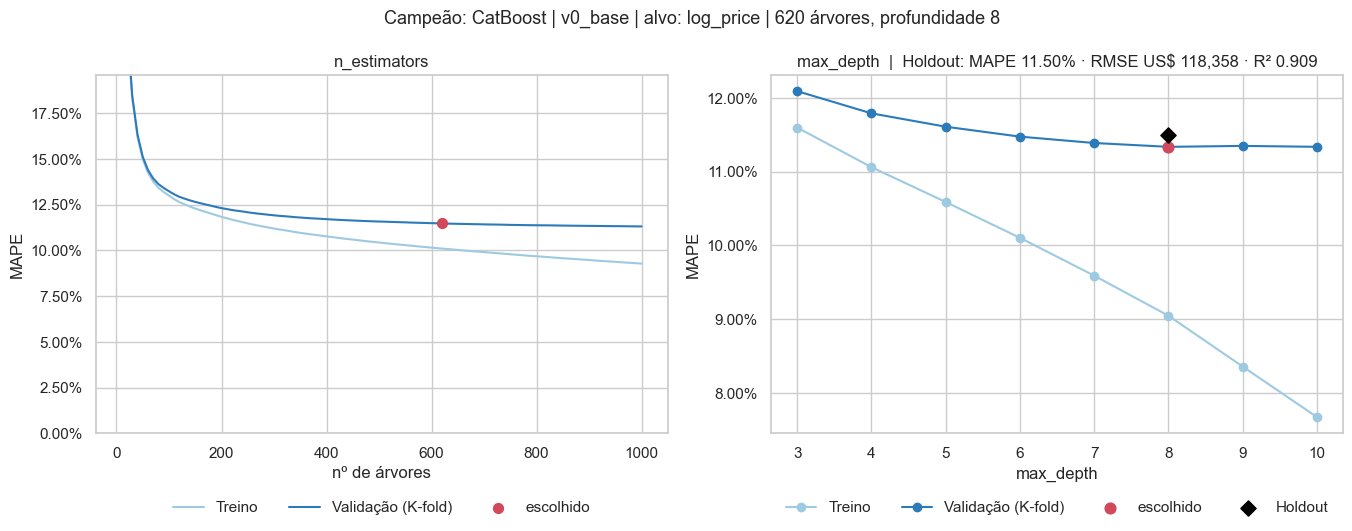

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

PASTA_RESULTADOS = f"{PASTA}\\Resultados parametrizacao v3"
PASTA_GRAFICOS = os.path.join(PASTA_RESULTADOS, "graficos")
os.makedirs(PASTA_GRAFICOS, exist_ok=True)

ALVOS_PLOT = ["log_price_sqft", "log_price"]

resultados = pd.read_csv(os.path.join(PASTA_RESULTADOS, "resultados.csv"))
curvas_arv = pd.read_csv(os.path.join(PASTA_RESULTADOS, "curvas_arvores.csv"))
curvas_prof = pd.read_csv(os.path.join(PASTA_RESULTADOS, "curvas_profundidade.csv"))

r = resultados[resultados.alvo.isin(ALVOS_PLOT)].sort_values("teste_MAPE").iloc[0]
filtro = lambda df: df[(df.variacao == r.variacao) & (df.alvo == r.alvo) & (df.modelo == r.modelo)]
ca, cp = filtro(curvas_arv), filtro(curvas_prof)
pct = plt.matplotlib.ticker.PercentFormatter(1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

ax[0].plot(ca.n_arvores, ca.mape_treino, label="Treino", color="#9ecae1")
ax[0].plot(ca.n_arvores, ca.mape_cv, label="Validação (K-fold)", color="#2b7bba")
esc = ca[ca.escolhido]
ax[0].scatter(esc.n_arvores, esc.mape_cv, color="#d1495b", zorder=4, s=50, label="escolhido")
ax[0].set(title="n_estimators", xlabel="nº de árvores", ylabel="MAPE",
          ylim=(0, ca.mape_cv.iloc[len(ca) // 10:].max() * 1.5))
ax[0].yaxis.set_major_formatter(pct)
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)

ax[1].plot(cp.max_depth, cp.mape_treino, marker="o", label="Treino", color="#9ecae1")
ax[1].plot(cp.max_depth, cp.mape_cv, marker="o", label="Validação (K-fold)", color="#2b7bba")
esc = cp[cp.escolhido]
ax[1].scatter(esc.max_depth, esc.mape_cv, color="#d1495b", zorder=4, s=60, label="escolhido")
ax[1].scatter(r.max_depth, r.teste_MAPE, color="black", marker="D", zorder=5, s=60, label="Holdout")
ax[1].set(title=f"max_depth  |  Holdout: MAPE {r.teste_MAPE:.2%} · RMSE US$ {r.teste_RMSE:,.0f} · R² {r.teste_R2:.3f}",
          xlabel="max_depth", ylabel="MAPE")
ax[1].yaxis.set_major_formatter(pct)
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)

fig.suptitle(f"Campeão: {r.modelo} | {r.variacao} | alvo: {r.alvo} | "
             f"{int(r.n_estimators)} árvores, profundidade {int(r.max_depth)}", fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(PASTA_GRAFICOS, f"campeao_{r.modelo}_{r.variacao}_{r.alvo}.png"),
            dpi=110, bbox_inches="tight")
plt.show()


### Onde o campeão erra

| Faixa de preço (holdout) | Preço | Erro mediano | Erro médio |
|---|---|---|---|
| Q1 (mais baratas) | US$ 81 mil – 295 mil | 10,2% | 16,6% |
| Q2 | US$ 296 mil – 400 mil | 7,1% | 9,6% |
| Q3 | US$ 400 mil – 510 mil | 7,2% | 10,5% |
| Q4 | US$ 510 mil – 700 mil | 7,1% | 9,2% |
| Q5 (mais caras) | US$ 704 mil – 6,9 mi | 9,2% | 11,5% |

- **Real × previsto:** os pontos acompanham a diagonal em toda a faixa de preço, com mais dispersão nos extremos.
- **Imóvel típico:** nas faixas centrais (Q2 a Q4), metade das casas tem erro abaixo de ~7%.
- **Média > mediana em todas as faixas:** o MAPE geral de 11,5% é puxado por poucos imóveis com erro alto. Não é o erro do imóvel típico.
- **Q1 (mais baratas):** um erro pequeno em dólares vira um percentual grande sobre um preço baixo, e é a faixa com maior erro médio.
- **Q5 (mais caras):** tem poucos exemplos de alto padrão no treino. Além disso, modelos de árvore não extrapolam acima do maior preço visto no treino, então imóveis fora dessa faixa tendem a ser subestimados. Por isso o deploy leva o alerta de faixa (`faixas_treino` nos metadados).

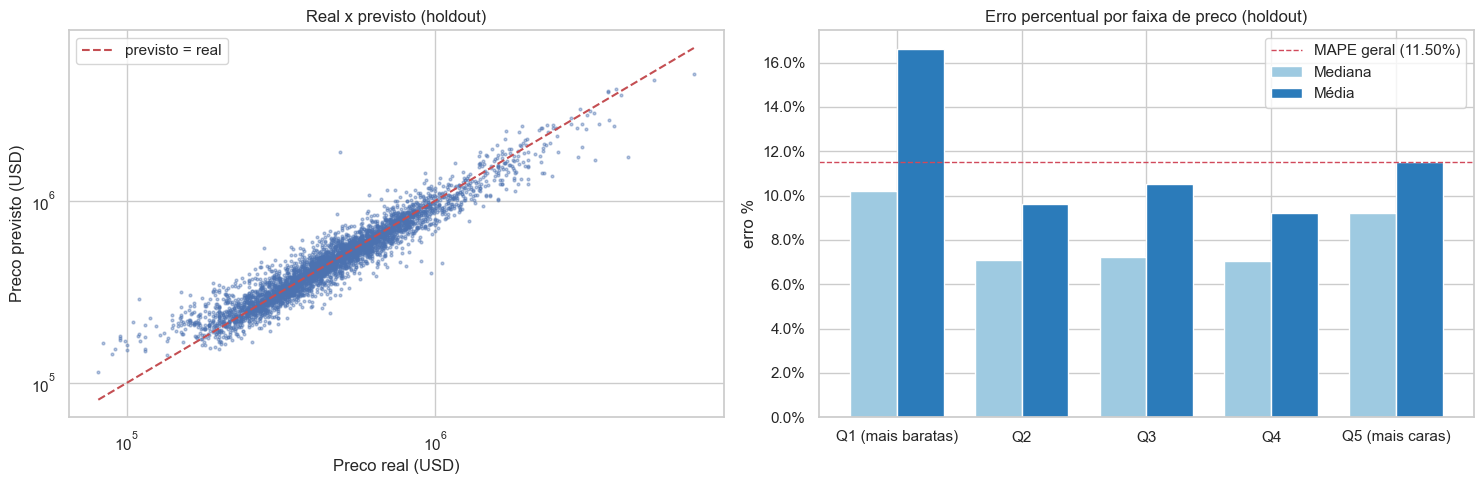

,preco_min,preco_max,imoveis,erro_mediano,erro_medio
faixa,,,,,
Q1 (mais baratas),"81,000","295,000",859,10.2%,16.6%
Q2,"295,500","399,500",859,7.1%,9.6%
Q3,"399,700","510,000",861,7.2%,10.5%
Q4,"510,250","700,000",862,7.1%,9.2%
Q5 (mais caras),"704,000","6,885,000",854,9.2%,11.5%


In [31]:
treino, teste, variaveis = carregar(r.variacao)
X_tr = np.ascontiguousarray(treino[variaveis].to_numpy(dtype="float64"))
X_te = np.ascontiguousarray(teste[variaveis].to_numpy(dtype="float64"))

modelo_final = criar_modelo(r.modelo, int(r.n_estimators), int(r.max_depth), r.alvo)
modelo_final.fit(X_tr, treino[r.alvo].to_numpy(dtype="float64"))

analise = pd.DataFrame({"real": teste["price"].values,
                        "previsto": para_preco(modelo_final.predict(X_te), teste, r.alvo)})
analise["erro_pct"] = (analise.previsto - analise.real).abs() / analise.real
analise["faixa"] = pd.qcut(analise.real, 5, labels=["Q1 (mais baratas)", "Q2", "Q3", "Q4", "Q5 (mais caras)"])

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].scatter(analise.real, analise.previsto, s=4, alpha=0.4)
lim = [analise.real.min(), analise.real.max()]
ax[0].plot(lim, lim, "r--", label="previsto = real")
ax[0].set(xscale="log", yscale="log", xlabel="Preco real (USD)", ylabel="Preco previsto (USD)",
          title="Real x previsto (holdout)")
ax[0].legend()

por_faixa = analise.groupby("faixa", observed=True).erro_pct.agg(Mediana="median", Média="mean")
por_faixa.plot.bar(ax=ax[1], color=["#9ecae1", "#2b7bba"], width=0.75)
ax[1].axhline(analise.erro_pct.mean(), color="#d1495b", ls="--", lw=1,
              label=f"MAPE geral ({analise.erro_pct.mean():.2%})")
ax[1].set(title="Erro percentual por faixa de preco (holdout)", xlabel="", ylabel="erro %")
ax[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax[1].tick_params(axis="x", rotation=0)
ax[1].legend()
plt.tight_layout()
plt.show()

display(analise.groupby("faixa", observed=True)
               .agg(preco_min=("real", "min"), preco_max=("real", "max"), imoveis=("real", "size"),
                    erro_mediano=("erro_pct", "median"), erro_medio=("erro_pct", "mean"))
               .style.format({"preco_min": "{:,.0f}", "preco_max": "{:,.0f}",
                              "erro_mediano": "{:.1%}", "erro_medio": "{:.1%}"}))

### Por que a base completa: MAPE no holdout por variação e alvo
O gráfico de barras mostra o melhor modelo de cada combinação, e a linha tracejada marca o melhor resultado (o campeão).
- As diferenças entre as variações ficam em **décimos de ponto percentual**. Nenhuma variação (corte de outliers, remoção de redundantes ou de variáveis pouco correlacionadas, novas features) superou a **v0_base**.
- `log_price` ficou igual ou melhor que `log_price_sqft` na maioria das variações.
- O **CatBoost** foi o melhor modelo em praticamente todas as combinações. LightGBM e XGBoost ficaram cerca de 0,1 a 0,2 p.p. atrás, com metade das árvores.
- **Decisão:** fica a base completa. É a mais simples e usa as mesmas colunas que chegam no unseen, sem regra extra de filtro no deploy.

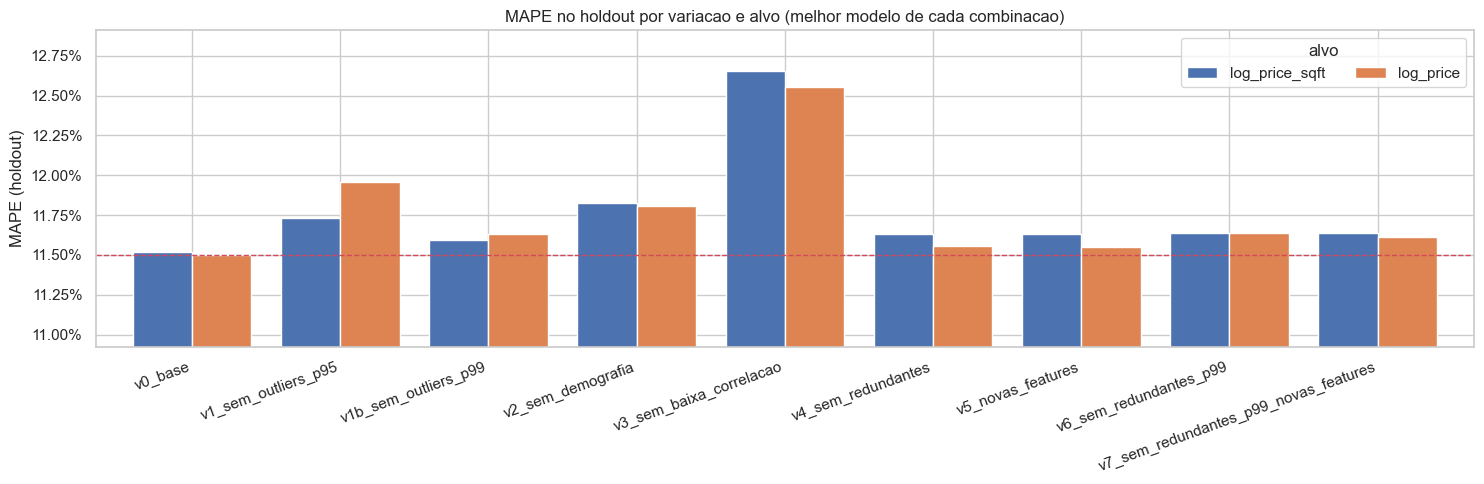

In [32]:
resultados = pd.read_csv(ARQ_RESULTADOS)
resultados = resultados[resultados.alvo.isin(ALVOS)]

melhor_por_alvo = resultados.loc[resultados.groupby(["variacao", "alvo"]).teste_MAPE.idxmin()]
grafico = melhor_por_alvo.pivot(index="variacao", columns="alvo", values="teste_MAPE")
grafico = grafico.reindex(index=[v for v in VARIACOES if v in grafico.index],
                          columns=[a for a in ALVOS if a in grafico.columns])

ax = grafico.plot.bar(figsize=(15, 5), width=0.8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title="MAPE no holdout por variacao e alvo (melhor modelo de cada combinacao)", xlabel="", ylabel="MAPE (holdout)",
       ylim=(grafico.min().min() * 0.95, grafico.max().max() * 1.02))
ax.axhline(grafico.min().min(), color="#d1495b", ls="--", lw=1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="alvo", ncol=len(ALVOS))
plt.tight_layout()
plt.show()

## Salvando o modelo campeão

In [21]:
import json
import joblib

resultados = pd.read_csv(ARQ_RESULTADOS)
resultados = resultados[resultados.alvo.isin(["log_price_sqft", "log_price"])]
campeao = resultados.sort_values("teste_MAPE").iloc[0]

variacao, alvo, nome_modelo = campeao["variacao"], campeao["alvo"], campeao["modelo"]
n, prof = int(campeao["n_estimators"]), int(campeao["max_depth"])

treino, teste, variaveis = carregar(variacao)
X_tr = np.ascontiguousarray(treino[variaveis].to_numpy(dtype="float64"))
y_tr = treino[alvo].to_numpy(dtype="float64")

modelo_final = criar_modelo(nome_modelo, n, prof, alvo)
modelo_final.fit(X_tr, y_tr)

PASTA_MODELO = os.path.join(PASTA, "Modelo final")
os.makedirs(PASTA_MODELO, exist_ok=True)

joblib.dump(modelo_final, os.path.join(PASTA_MODELO, "modelo_final.joblib"))

metadados = {
    "variacao": variacao,
    "alvo": alvo,
    "modelo": nome_modelo,
    "lr": LR,
    "n_estimators": n,
    "max_depth": prof,
    "variaveis": variaveis,
    "faixas_treino": {v: [float(treino[v].min()), float(treino[v].max())] for v in variaveis},
    "metricas": {"treino_MAPE": float(campeao["treino_MAPE"]), "cv_MAPE": float(campeao["mape_cv"]),
                 "teste_MAPE": float(campeao["teste_MAPE"]), "teste_MAE": float(campeao["teste_MAE"]),
                 "teste_RMSE": float(campeao["teste_RMSE"]), "teste_R2": float(campeao["teste_R2"])},
}
with open(os.path.join(PASTA_MODELO, "metadados.json"), "w", encoding="utf-8") as f:
    json.dump(metadados, f, ensure_ascii=False, indent=2)

print(f"Campeão salvo: {nome_modelo} | {variacao} | alvo {alvo} | {n} árvores | profundidade {prof}")
print(f"Holdout: MAPE {campeao['teste_MAPE']:.2%} | R² {campeao['teste_R2']:.3f}")
print(f"Pasta: {PASTA_MODELO}")
display(pd.DataFrame({
    "Etapa": ["Treino (80%, dados que o modelo viu)",
              "Validação cruzada (K-fold dentro dos 80%)",
              "Holdout (20%, nunca visto)"],
    "MAPE": [campeao["treino_MAPE"], campeao["mape_cv"], campeao["teste_MAPE"]],
}).style.format({"MAPE": "{:.2%}"}).hide(axis="index"))

Campeão salvo: CatBoost | v0_base | alvo log_price | 620 árvores | profundidade 8
Holdout: MAPE 11.50% | R² 0.909
Pasta: C:\Users\PICHAU\Downloads\DESAFIO DATA SCIENCE\Modelo final


Etapa,MAPE
"Treino (80%, dados que o modelo viu)",9.27%
Validação cruzada (K-fold dentro dos 80%),11.34%
"Holdout (20%, nunca visto)",11.50%


# Engenharia Reversa 

## Variáveis mais importantes (SHAP)

O SHAP mostra quanto cada variável empurra a previsão para cima ou para baixo em cada imóvel. Como o alvo está em log, o efeito é aproximadamente percentual sobre o preço (0,1 ≈ +10%). As variáveis estão ordenadas pela importância média, e a cor indica o valor da variável (vermelho = alto, azul = baixo).

- **Localização (`lat`)** é a variável mais importante: o preço sobe do sul até a faixa central (Seattle e Bellevue) e volta a cair no extremo norte. `long` tem efeito menor, e imóveis mais a leste tendem a valer um pouco menos.
- **Tamanho e padrão (`sqft_living`, `grade`)** vêm logo depois: quanto maior a área útil e o padrão de construção, maior o preço. São os efeitos de maior alcance, chegando a +40%.
- **Demografia do CEP (`per_bchlr`, `per_prfsnl`, `hous_val_amt`)** tem três variáveis entre as sete primeiras. A escolaridade e o valor médio dos imóveis do bairro carregam informação que as características da casa não têm, o que justifica a junção com a base demográfica.
- **`view`:** a maioria dos imóveis não tem vista e fica perto de zero, mas os que têm recebem até +30%.
- **`sqft_living15`:** o tamanho das casas vizinhas também puxa o preço, um efeito de vizinhança.
- **Variáveis correlacionadas dividem a importância:** `bathrooms` e `sqft_above` aparecem baixas porque boa parte do que explicam já está em `sqft_living`. Isso não quer dizer que sejam irrelevantes isoladamente.

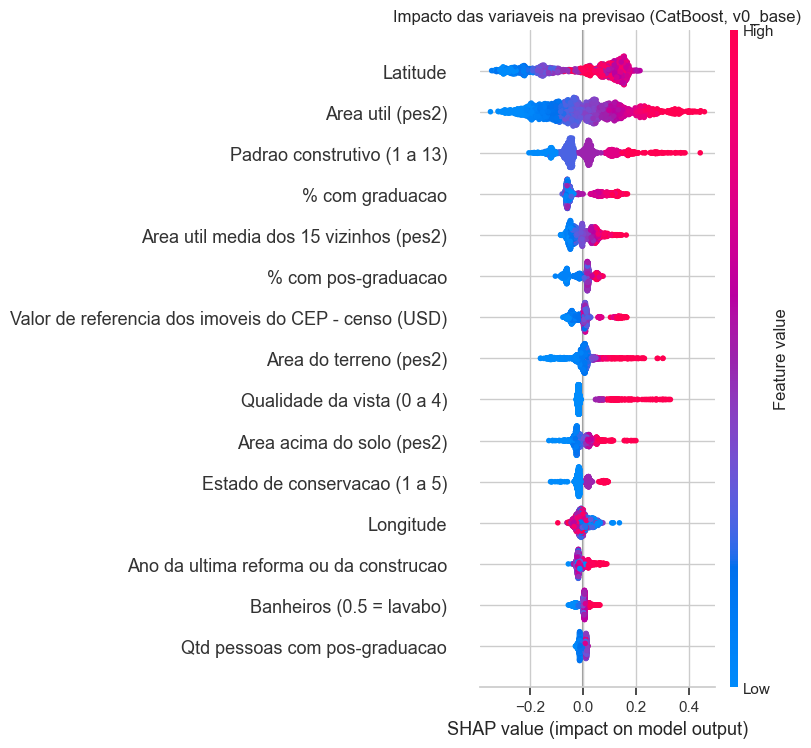

,media |SHAP|
Latitude,0.137212
Area util (pes2),0.124025
Padrao construtivo (1 a 13),0.074147
% com graduacao,0.068019
Area util media dos 15 vizinhos (pes2),0.038996
% com pos-graduacao,0.035927
Valor de referencia dos imoveis do CEP - censo (USD),0.030765
Area do terreno (pes2),0.030294
Qualidade da vista (0 a 4),0.029284
Area acima do solo (pes2),0.027397


In [33]:
import json, joblib, shap

PASTA_MODELO = os.path.join(PASTA, "Modelo final")
modelo_final = joblib.load(os.path.join(PASTA_MODELO, "modelo_final.joblib"))
with open(os.path.join(PASTA_MODELO, "metadados.json"), encoding="utf-8") as f:
    meta = json.load(f)

treino, teste, _ = carregar(meta["variacao"])
variaveis = meta["variaveis"]

# Nomes traduzidos para os gráficos (o cabeçalho das variações é "orig - significado")
colunas = pd.read_csv(f"{PASTA_VARIACOES}\\{meta['variacao']}.csv", nrows=0, encoding="utf-8-sig").columns
nomes = {c.split(" - ")[0]: c.split(" - ", 1)[1] for c in colunas if " - " in c}
rotulo = lambda v: nomes.get(v, v)

amostra = teste[variaveis].sample(min(2000, len(teste)), random_state=SEED)
explainer = shap.TreeExplainer(modelo_final)
shap_values = explainer.shap_values(amostra.to_numpy(dtype="float64"))

shap.summary_plot(shap_values, amostra.rename(columns=rotulo), max_display=15, show=False)
plt.title(f"Impacto das variaveis na previsao ({meta['modelo']}, {meta['variacao']})")
plt.show()

importancia = pd.Series(np.abs(shap_values).mean(axis=0), index=[rotulo(v) for v in variaveis]).sort_values(ascending=False)
display(importancia.head(15).to_frame("media |SHAP|"))

### Importância nativa do modelo

É o peso que o próprio CatBoost dá a cada variável: quanto a previsão muda, em média, quando a variável é usada nas divisões das árvores. Os valores somam 100%. A importância nativa mostra o quanto o modelo usa cada variável, e o SHAP mostra a direção do efeito (se puxa o preço para cima ou para baixo).

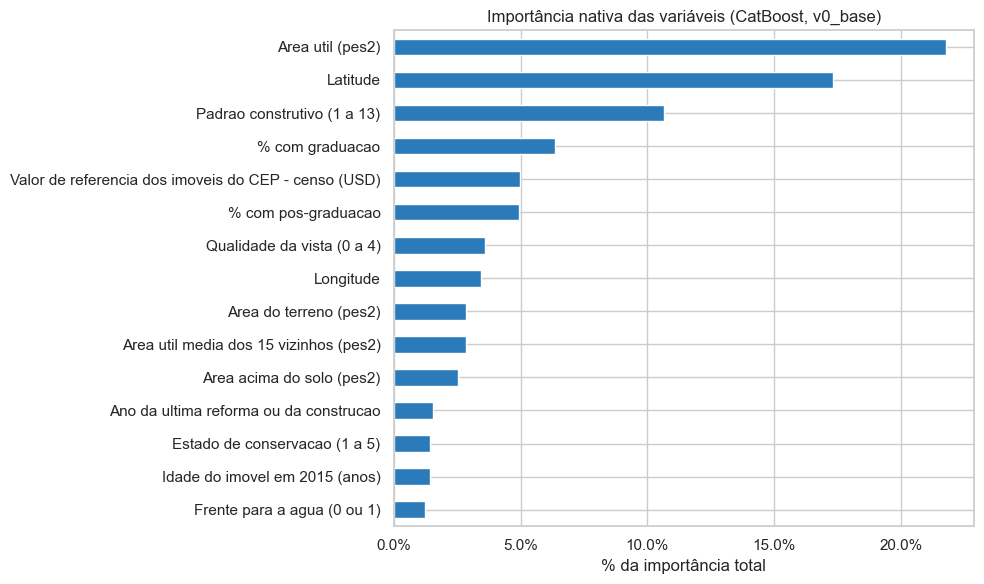

,importancia
Area util (pes2),21.8%
Latitude,17.3%
Padrao construtivo (1 a 13),10.6%
% com graduacao,6.4%
Valor de referencia dos imoveis do CEP - censo (USD),5.0%
% com pos-graduacao,4.9%
Qualidade da vista (0 a 4),3.6%
Longitude,3.4%
Area do terreno (pes2),2.9%
Area util media dos 15 vizinhos (pes2),2.9%


In [34]:
importancia_nativa = (pd.Series(modelo_final.feature_importances_, index=meta["variaveis"])
                        .sort_values(ascending=False))
importancia_nativa = importancia_nativa / importancia_nativa.sum()

ax = importancia_nativa.head(15).rename(rotulo).sort_values().plot.barh(figsize=(10, 6), color="#2b7bba")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title=f"Importância nativa das variáveis ({meta['modelo']}, {meta['variacao']})",
       xlabel="% da importância total", ylabel="")
plt.tight_layout()
plt.show()

display(importancia_nativa.head(15).rename(rotulo).to_frame("importancia").style.format("{:.1%}"))

### Limites do modelo

Modelos de árvore só conhecem o que viram no treino, e isso cria dois limites.

**1. Na entrada (variáveis):** cada variável tem uma faixa de mínimo e máximo no treino, salva em `faixas_treino` nos metadados. Uma casa com valor acima do máximo é tratada como se estivesse no máximo. Por exemplo, o modelo não sabe que uma casa maior que a maior do treino deveria valer mais.
- No holdout, só 3 de 4.295 imóveis têm alguma variável fora da faixa. Um deles tem `sqft_living` de ~13.500 pés², acima do máximo de 12.050 do treino.
- No deploy, essa mesma checagem gera um alerta de faixa para cada imóvel previsto.

**2. Na saída (preço):** cada árvore devolve médias de casas vistas no treino. Por isso a previsão fica concentrada no meio e é puxada para o centro nos extremos.
- **Teto das previsões:** o treino vai até US$ 7,7 mi, mas a maior previsão no holdout foi de US$ 5,0 mi. A casa mais cara do holdout (US$ 6,9 mi) foi prevista em US$ 5,0 mi (−28%).
- **Viés por decil:** o modelo superestima as casas mais baratas (D1, cerca de +17%) e subestima as mais caras (D10, cerca de −7%). Do D2 ao D9 o viés fica entre −2% e +4%.
- Esse viés no D1 explica o erro médio mais alto da faixa Q1 em "Onde o campeão erra".

**Conclusão:** o modelo é confiável para a faixa típica do mercado. Para imóveis de alto padrão (acima de ~US$ 3 mi) e para os muito baratos, a previsão deve ser lida como referência e acompanhada do alerta de faixa.

Imóveis do holdout com ao menos uma variável fora da faixa: 3 de 4295


,min_treino,max_treino,fora_holdout
Area util (pes2),370,"12,050",1
Latitude,47.1559,47.7776,0
Padrao construtivo (1 a 13),3,13,0
% com graduacao,6,39,0
Valor de referencia dos imoveis do CEP - censo (USD),"141,500","790,300",0
% com pos-graduacao,2,24,0
Qualidade da vista (0 a 4),0,4,0
Longitude,-122.519,-121.315,0
Area do terreno (pes2),520,"1,651,359",0
Area util media dos 15 vizinhos (pes2),399,"6,210",0


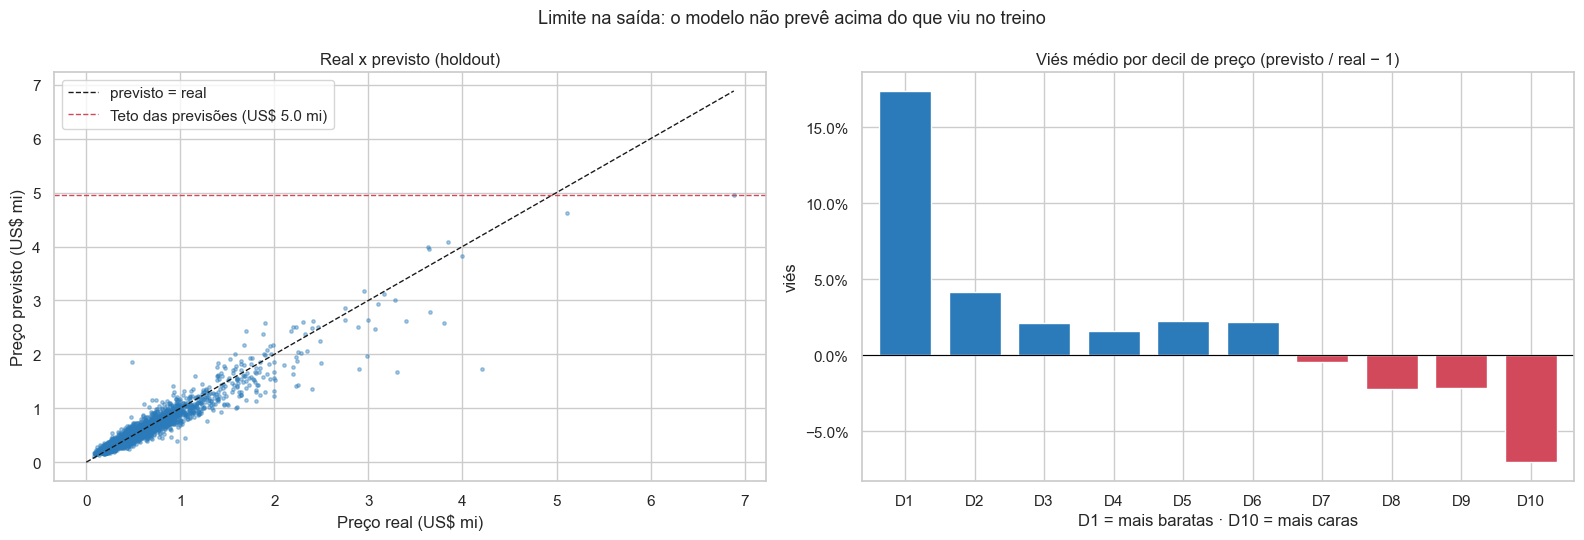

In [42]:
faixas = pd.DataFrame(meta["faixas_treino"], index=["min_treino", "max_treino"]).T

def fora_da_faixa(df):
    return pd.DataFrame({v: (df[v] < faixas.loc[v, "min_treino"]) | (df[v] > faixas.loc[v, "max_treino"])
                         for v in faixas.index})

previsto = para_preco(modelo_final.predict(teste[meta["variaveis"]].to_numpy(dtype="float64")), teste, meta["alvo"])
fora = fora_da_faixa(teste)

# 1. Limite na entrada: faixa do treino de todas as variáveis do modelo (ordem de importância)
ordem = list(importancia_nativa.index)
numero = lambda x: f"{x:,.4f}".rstrip("0").rstrip(".")

print(f"Imóveis do holdout com ao menos uma variável fora da faixa: {fora.any(axis=1).sum()} de {len(teste)}")
display(faixas.loc[ordem]
              .assign(fora_holdout=fora.sum()[ordem])
              .rename(index=rotulo)
              .style.format({"min_treino": numero, "max_treino": numero}))

# 2. Limite na saída: a previsão satura nas casas mais caras
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))

ax[0].scatter(teste["price"] / 1e6, previsto / 1e6, s=6, alpha=0.4, color="#2b7bba")
lim = [0, teste["price"].max() / 1e6]
ax[0].plot(lim, lim, "k--", lw=1, label="previsto = real")
ax[0].axhline(previsto.max() / 1e6, color="#d1495b", ls="--", lw=1,
              label=f"Teto das previsões (US$ {previsto.max() / 1e6:.1f} mi)")
ax[0].set(title="Real x previsto (holdout)", xlabel="Preço real (US$ mi)", ylabel="Preço previsto (US$ mi)")
ax[0].legend(loc="upper left")

decil = pd.qcut(teste["price"], 10, labels=[f"D{i}" for i in range(1, 11)])
vies = (pd.Series(previsto / teste["price"].values - 1).groupby(decil.values, observed=True).mean())
vies.plot.bar(ax=ax[1], color=["#d1495b" if x < 0 else "#2b7bba" for x in vies], width=0.75)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax[1].set(title="Viés médio por decil de preço (previsto / real − 1)", xlabel="D1 = mais baratas · D10 = mais caras", ylabel="viés")
ax[1].tick_params(axis="x", rotation=0)

fig.suptitle("Limite na saída: o modelo não prevê acima do que viu no treino", fontsize=13)
plt.tight_layout()
plt.show()

## Conclusão

**Modelo escolhido:** CatBoost treinado na base completa (v0_base), com alvo `log(price)`, LR = 0,05, 620 árvores e profundidade 8. Os demais hiperparâmetros ficaram no default.

| Etapa | MAPE |
|---|---|
| Treino | 9,27% |
| Validação cruzada (K-fold) | 11,34% |
| Holdout (nunca visto) | **11,50%** |

Holdout: RMSE US$ 118.358 · R² 0,909.

**Por que esse modelo**
- O CatBoost foi o melhor em praticamente todas as combinações. LightGBM e XGBoost ficaram de 0,1 a 0,2 p.p. atrás.
- Nenhuma variação da base (outliers, redundantes, novas features) trouxe ganho real sobre a base completa, que é a mais simples de manter no deploy.
- A regra de parada escolheu o cotovelo da curva: um modelo mais simples, com quase o mesmo erro do ponto de mínimo.

**Generalização**
- O holdout ficou apenas 0,16 p.p. acima da validação cruzada. O desempenho em dados novos é o mesmo estimado na parametrização, sem sinal de overfitting.
- O erro típico é menor que o MAPE geral: nas faixas centrais de preço, metade das casas erra menos de ~7%.

**Variáveis mais importantes:** a importância nativa e o SHAP concordam.
- **Área útil (`sqft_living`), localização (`lat`) e padrão de construção (`grade`)** somam ~50% da importância do modelo.
- **A demografia do CEP** (escolaridade e valor médio dos imóveis do bairro) aparece logo em seguida, o que confirma o ganho da junção com a base demográfica.

**Limites**
- O modelo superestima as casas mais baratas e subestima as de alto padrão. As previsões não passam de ~US$ 5 mi, mesmo com casas de até US$ 7,7 mi no treino.
- Imóveis com variáveis fora da faixa do treino recebem um alerta de faixa no deploy.